Q12: Data Aggregation

Analyzing retail sales performance by region.

Use Retail_Sales_Data.csv from the same folder. This is the existing generated practice dataset, not real observations.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Retail_Sales_Data.csv")
df["TransactionDate"] = pd.to_datetime(df["TransactionDate"])

print(df.head())
df.info()
print("Missing Values:")
print(df.isnull().sum())

  TransactionID TransactionDate Region  ... QuantitySold  UnitPrice  SalesAmount
0        RS0001      2025-05-06  North  ...            5   13052.75     65263.75
1        RS0002      2025-05-17  South  ...            3   17059.11     51177.33
2        RS0003      2025-01-05  North  ...            3     401.71      1205.13
3        RS0004      2025-01-27   West  ...            1     534.48       534.48
4        RS0005      2025-02-22  North  ...            1   12518.23     12518.23

[5 rows x 7 columns]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   TransactionID    320 non-null    object        
 1   TransactionDate  320 non-null    datetime64[ns]
 2   Region           320 non-null    object        
 3   ProductCategory  320 non-null    object        
 4   QuantitySold     320 non-null    int64         
 5   UnitPrice   

In [2]:
# Total sales by region
regional_sales = df.groupby("Region")["SalesAmount"].sum()
regional_sales = regional_sales.sort_values(ascending=False)
print("Regional Sales:")
print(regional_sales)
print("\nTotal Sales:", round(regional_sales.sum(), 2))
print("Top Region:", regional_sales.idxmax())

Regional Sales:
Region
East     1698905.09
South    1377072.57
West     1284922.31
North    1076181.45
Name: SalesAmount, dtype: float64

Total Sales: 5437081.42
Top Region: East


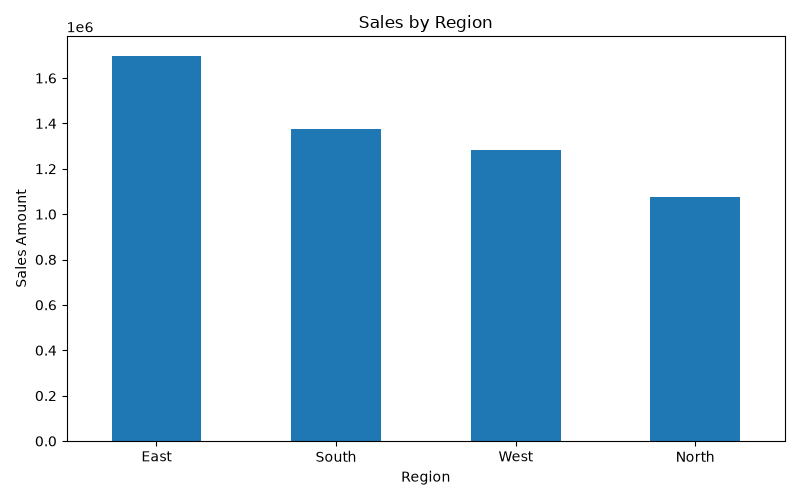

In [3]:
# Compare regional sales
regional_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

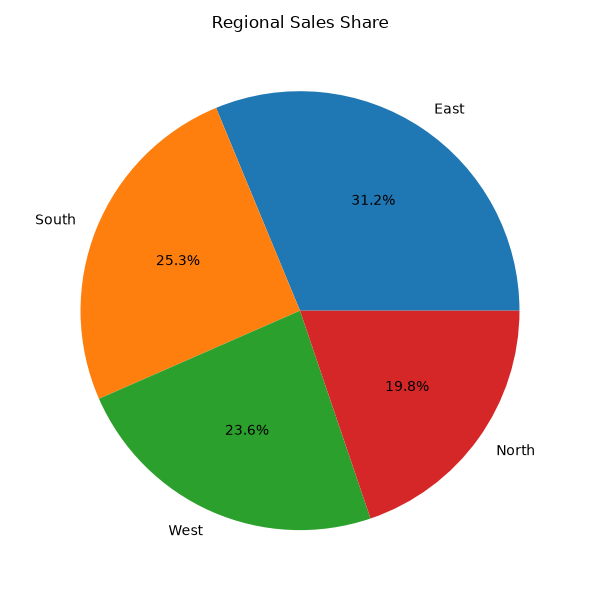

In [4]:
# Regional sales share
regional_sales.plot(kind="pie", autopct="%1.1f%%", figsize=(6, 6))
plt.title("Regional Sales Share")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [5]:
# Sales by region and product category
category_sales = df.groupby(["Region", "ProductCategory"])["SalesAmount"].sum()
category_sales = category_sales.unstack(fill_value=0)
print(category_sales)

ProductCategory   Clothing  Electronics  Furniture  Groceries
Region                                                       
East             170426.18   1181603.03  324492.99   22382.89
North             88969.85    610659.57  354800.79   21751.24
South            130530.86    835316.94  387559.17   23665.60
West             173872.12    736480.36  357921.97   16647.86


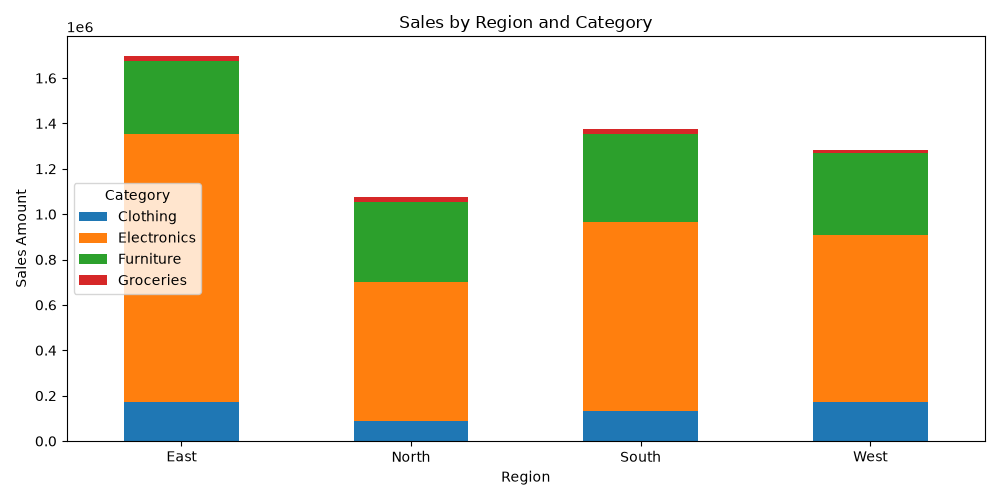

In [6]:
# Stacked sales chart
category_sales.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Sales by Region and Category")
plt.xlabel("Region")
plt.ylabel("Sales Amount")
plt.xticks(rotation=0)
plt.legend(title="Category")
plt.tight_layout()
plt.show()

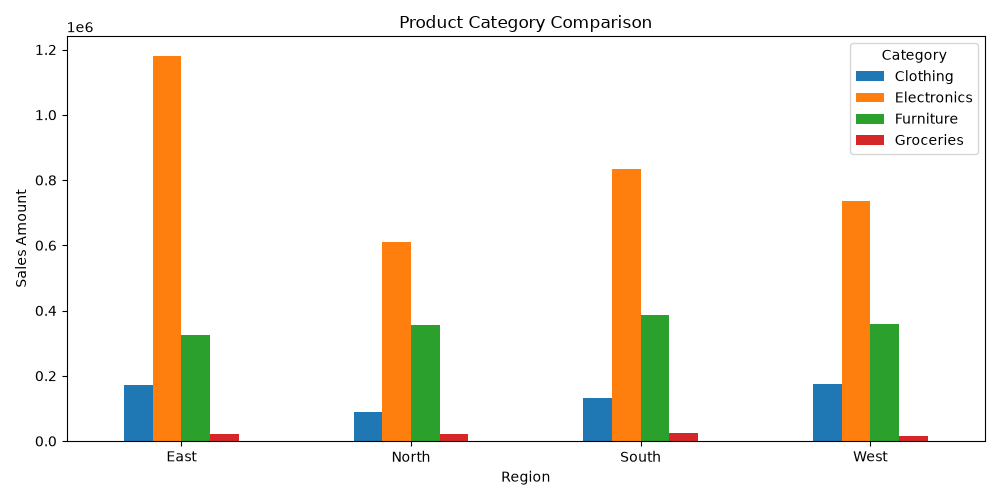

In [7]:
# Grouped sales chart
category_sales.plot(kind="bar", figsize=(10, 5))
plt.title("Product Category Comparison")
plt.xlabel("Region")
plt.ylabel("Sales Amount")
plt.xticks(rotation=0)
plt.legend(title="Category")
plt.tight_layout()
plt.show()